# Joint PLDS batch fit on real data

Fits the Poisson LDS and the stim matrix B jointly on control and stim reaches (target A),
then shows the smoothed latents.

1. `fit_initial` on control trials (no stim, so B drops out).
2. `fit_batch` (EM) on control + stim trials together. E-step: joint EKF over
   [x; vec(B)]. M-step: refit A, C, d, Q, b with B at its posterior mean.
3. `batch_smooth_latents` with the fitted B for the smoothed latents.

In [3]:
import os
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import json
from pathlib import Path

import equinox as eqx
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
from simulations import make_toeplitz_V

from wasabi import BPosterior, TrialBuffer, batch_smooth_latents, fit_batch, fit_initial, make_poisson_lds
from wasabi.utils import softplus

# Load data

In [4]:
PERI_ROOT = Path("/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Nike/20251203_NRR_RW011/results/checkpoints/PeriStim")
TARGET = "target_A"
STIM_BLOCKS = [12, 13, 14, 15, 16, 17, 18, 19, 20, 21]  # 8 contiguous channels each
STIM_DUR_MS = 100.0

control_files = sorted((PERI_ROOT / "control_reaches" / TARGET).glob("peristim__*.npz"))
stim_files = sorted(
    f for br in STIM_BLOCKS for f in (PERI_ROOT / "stim_reaches" / TARGET).glob(f"*BR_{br:03d}_*.npz")
)
print(f"{len(control_files)} control files, {len(stim_files)} stim files")

3 control files, 10 stim files


In [5]:
# Control trials: every bin observed
control_counts = np.concatenate([np.load(f)["NPRW_counts"] for f in control_files])  # (trials, ch, bins)
t_ms = np.load(control_files[0])["NPRW_rel_t"]
n_ch = control_counts.shape[1]

# The stim peristim extraction drops the blanked window instead of masking it, leaving a
# gap in the time axis. Reinsert it as NaN bins so stim trials share the control time axis.
stim_t_raw = np.load(stim_files[0])["NPRW_rel_t"]
gap = int(np.argmax(np.diff(stim_t_raw)))
n_insert = len(t_ms) - len(stim_t_raw)
assert np.allclose(np.concatenate([stim_t_raw[: gap + 1], stim_t_raw[gap + 1 :]]),
                   np.delete(t_ms, np.arange(gap + 1, gap + 1 + n_insert)), atol=1.5)
stim_bins = np.flatnonzero((t_ms >= 0) & (t_ms < STIM_DUR_MS))
blank_ms = (t_ms[gap], t_ms[gap + n_insert + 1])

stim_counts, stim_inputs, patterns, pattern_id = [], [], [], []
for j, f in enumerate(stim_files):
    npz = np.load(f, allow_pickle=True)
    counts = npz["NPRW_counts"]
    channels = np.asarray(json.loads(npz["nprw_meta_json"].item())["stim_channels"], dtype=int) - 1
    blank = np.full((counts.shape[0], n_ch, n_insert), np.nan)
    stim_counts.append(np.concatenate([counts[:, :, : gap + 1], blank, counts[:, :, gap + 1 :]], axis=2))

    pattern = np.zeros(n_ch)
    pattern[channels] = 1.0
    s = np.zeros((counts.shape[0], len(t_ms), n_ch))
    s[:, stim_bins] = pattern
    stim_inputs.append(s)
    patterns.append(pattern)
    pattern_id += [j] * counts.shape[0]

stim_counts = np.concatenate(stim_counts)
patterns = np.stack(patterns)
pattern_id = np.asarray(pattern_id)

# (trials, T, N) for the model; keep is False where any channel is blanked
Y_control = jnp.asarray(control_counts.transpose(0, 2, 1))
Y_stim = jnp.asarray(stim_counts.transpose(0, 2, 1))
S_control = jnp.zeros_like(Y_control)
S_stim = jnp.asarray(np.concatenate(stim_inputs))
keep_control = jnp.all(jnp.isfinite(Y_control), axis=2)
keep_stim = jnp.all(jnp.isfinite(Y_stim), axis=2)

print(f"control {Y_control.shape}, stim {Y_stim.shape}, {len(patterns)} patterns")
print("stim channels per pattern:", [np.flatnonzero(p)[[0, -1]].tolist() for p in patterns])
print(f"blanked bins {np.flatnonzero(~np.asarray(keep_stim[0]))}, stim bins {stim_bins}")

control (27, 70, 128), stim (72, 70, 128), 10 patterns
stim channels per pattern: [[0, 7], [4, 11], [8, 15], [12, 19], [16, 23], [20, 27], [24, 31], [28, 35], [32, 39], [36, 43]]
blanked bins [39 40 41 42 43 44 45], stim bins [40 41 42 43 44]


# Fit

In [ ]:
STATE_DIM = 4
BETA_STIM = 1.0
BETA_EMIT = 1.0
SPREAD_WIDTH = 3.0  # Toeplitz stim spread V across neighbouring channels
RELINEARIZE_ITERS = 0  # iterated-smoother passes per trial; 0 = plain EKF (fit better)

model = make_poisson_lds(
    STATE_DIM, jnp.asarray(make_toeplitz_V(n_ch, SPREAD_WIDTH)), jr.key(0),
    mean_rate=jnp.nanmean(Y_control, axis=(0, 1)), beta_stim=BETA_STIM, beta_emit=BETA_EMIT,
)

# 1. Control trials only: B drops out, so this fits A, C, d, Q
control_buffer = TrialBuffer.empty(len(Y_control), len(t_ms), n_ch).extend(Y_control, S_control, keep_control)
model, init_losses = fit_initial(model, control_buffer, num_steps=500, relinearize_iters=RELINEARIZE_ITERS)
print(f"control fit NLL per bin: {init_losses[0]:.4f} -> {init_losses[-1]:.4f}")

In [ ]:
# 2. Joint batch EM on control + stim trials. Control trials have zero stim input, so they
# only constrain the dynamics; stim trials constrain both the dynamics and B.
Y_all = jnp.concatenate([Y_control, Y_stim])
S_all = jnp.concatenate([S_control, S_stim])
keep_all = jnp.concatenate([keep_control, keep_stim])
is_stim = np.r_[np.zeros(len(Y_control), bool), np.ones(len(Y_stim), bool)]

buffer = TrialBuffer.empty(len(Y_all), len(t_ms), n_ch).extend(Y_all, S_all, keep_all)
model, B_post, em_losses = fit_batch(
    model, BPosterior.from_prior(STATE_DIM, n_ch, prior_var=1.0), buffer,
    num_iters=10, refit_steps=50, relinearize_iters=RELINEARIZE_ITERS,
)
B_fit = B_post.B
print("NLL per bin at the end of each EM iteration:", np.round(np.asarray(em_losses[:, -1]), 4))
print(f"|B| = {float(jnp.linalg.norm(B_fit)):.3f}, b = {float(model.dynamics.b):.3f}")
print("singular values of A:", np.round(np.asarray(jnp.linalg.svd(model.dynamics.A, compute_uv=False)), 4))

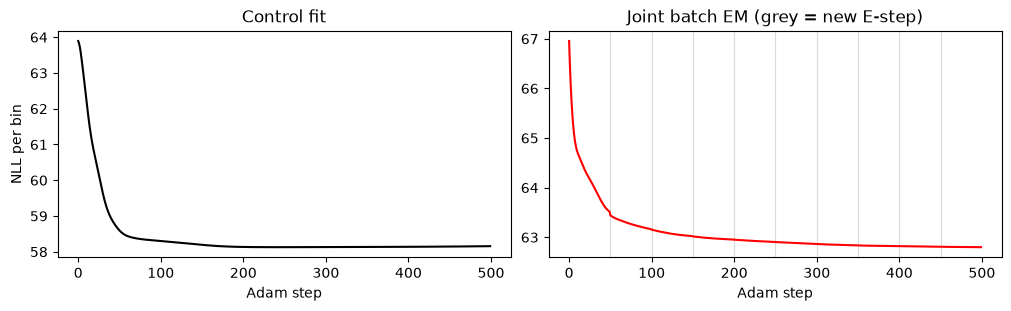

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].plot(init_losses, color="k")
axes[0].set_title("Control fit"); axes[0].set_xlabel("Adam step"); axes[0].set_ylabel("NLL per bin")
axes[1].plot(np.asarray(em_losses).ravel(), color="r")
for i in range(1, len(em_losses)):
    axes[1].axvline(i * em_losses.shape[1], color="0.85", lw=0.8, zorder=0)
axes[1].set_title("Joint batch EM (grey = new E-step)"); axes[1].set_xlabel("Adam step")
plt.show()

# Smoothed latents

The latent basis is only defined up to rotation, so the smoothed means are rotated onto
their principal axes (an orthogonal rotation, so C x is unchanged): z₁ has the most variance.

In [ ]:
# 3. RTS smoother with B fixed at the fitted posterior mean
posts = batch_smooth_latents(model, B_fit, Y_all, S_all, keep_all, relinearize_iters=RELINEARIZE_ITERS)
x_smooth = np.asarray(posts.smoothed_means)          # (trials, T, K)
x_cov = np.asarray(posts.smoothed_covs)              # (trials, T, K, K)

flat = x_smooth.reshape(-1, STATE_DIM)
_, _, Wt = np.linalg.svd(flat - flat.mean(axis=0), full_matrices=False)
R = Wt.T                                             # columns are the principal axes
z = x_smooth @ R
z_sd = np.sqrt(np.einsum("ki,ntkl,li->nti", R, x_cov, R))   # per-axis smoothed std

z_control, z_stim = z[~is_stim], z[is_stim]

# Plots start here; the trimmed bins are still used by the fit and the smoother
PLOT_FROM_MS = -400.0
tp = t_ms >= PLOT_FROM_MS
print("fraction of latent variance per axis:", np.round(np.var(z, axis=(0, 1)) / np.var(z, axis=(0, 1)).sum(), 3))

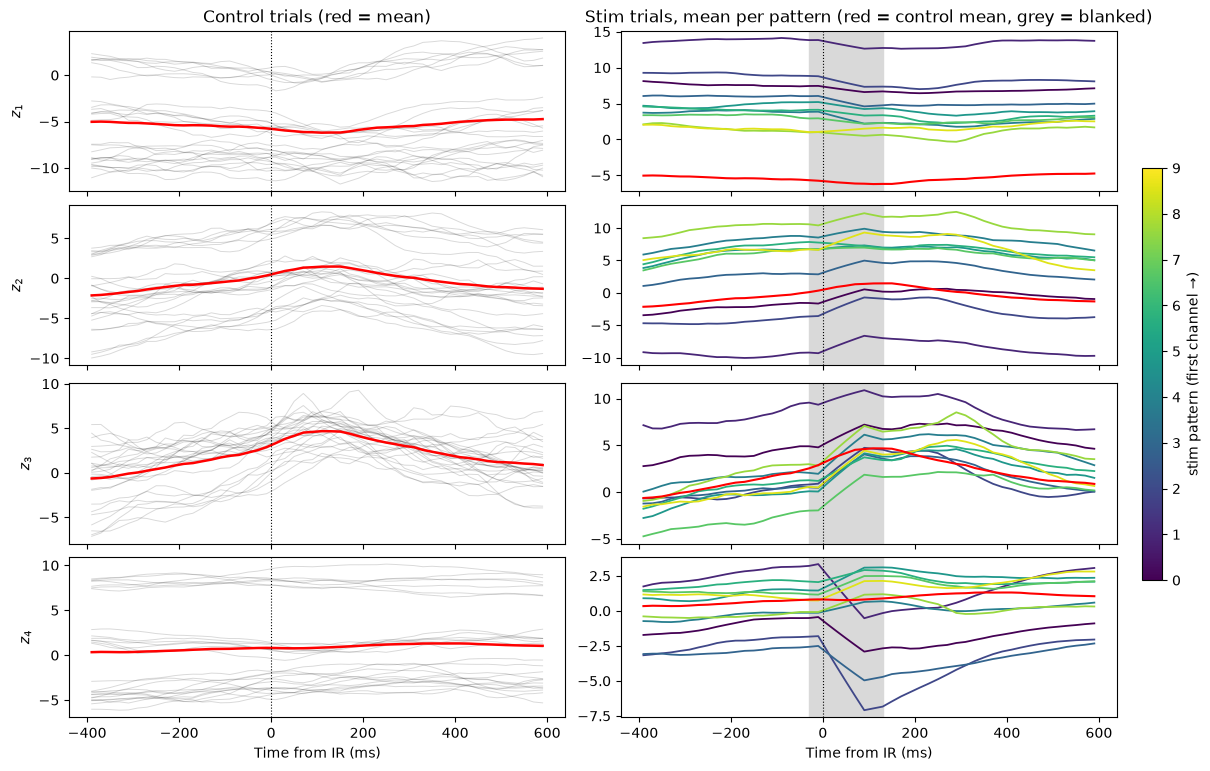

In [10]:
colors = plt.cm.viridis(np.linspace(0, 0.95, len(patterns)))

fig, axes = plt.subplots(STATE_DIM, 2, figsize=(12, 1.9 * STATE_DIM), constrained_layout=True, sharex=True)
for k in range(STATE_DIM):
    # Left: control trials and their mean
    ax = axes[k, 0]
    ax.plot(t_ms[tp], z_control[:, tp, k].T, color="k", alpha=0.15, lw=0.7)
    ax.plot(t_ms[tp], z_control[:, tp, k].mean(axis=0), color="r", lw=1.8)
    ax.set_ylabel(f"$z_{k + 1}$")

    # Right: mean per stim pattern, control mean for reference
    ax = axes[k, 1]
    for j, color in enumerate(colors):
        ax.plot(t_ms[tp], z_stim[pattern_id == j][:, tp, k].mean(axis=0), color=color, lw=1.3)
    ax.plot(t_ms[tp], z_control[:, tp, k].mean(axis=0), color="r", lw=1.5)
    ax.axvspan(*blank_ms, color="0.85", zorder=0)

for ax in axes.ravel():
    ax.axvline(0, color="k", ls=":", lw=0.8)
axes[0, 0].set_title("Control trials (red = mean)")
axes[0, 1].set_title("Stim trials, mean per pattern (red = control mean, grey = blanked)")
axes[-1, 0].set_xlabel("Time from IR (ms)"); axes[-1, 1].set_xlabel("Time from IR (ms)")
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, len(patterns) - 1))
fig.colorbar(sm, ax=axes[:, 1], label="stim pattern (first channel →)", shrink=0.6)
plt.show()

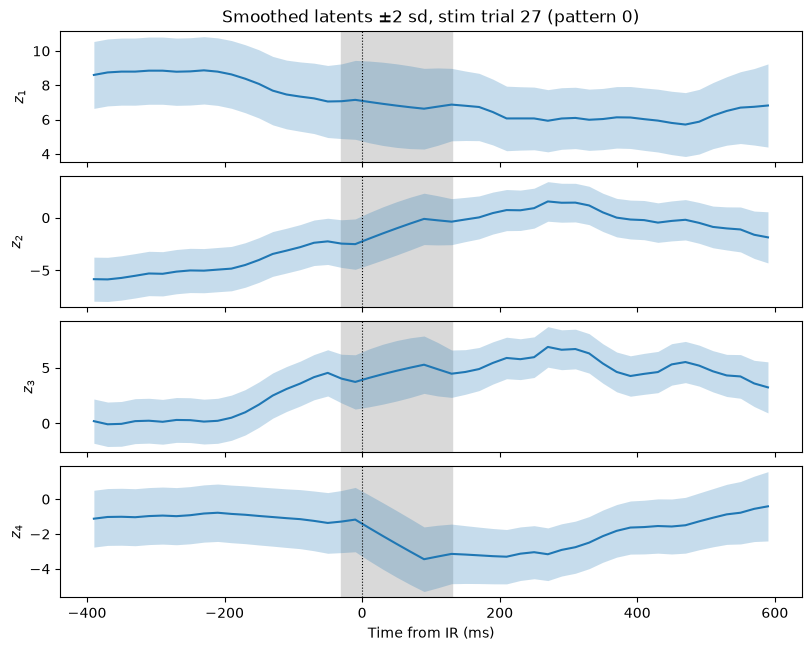

In [11]:
# One example stim trial with its smoothed uncertainty. Inside the blanked window there are no
# observations, so the band widens there: the latent is carried by the dynamics and B alone.
trial = int(np.flatnonzero(is_stim)[0])

fig, axes = plt.subplots(STATE_DIM, 1, figsize=(8, 1.6 * STATE_DIM), constrained_layout=True, sharex=True)
for k, ax in enumerate(axes):
    m, sd = z[trial, tp, k], z_sd[trial, tp, k]
    ax.fill_between(t_ms[tp], m - 2 * sd, m + 2 * sd, color="tab:blue", alpha=0.25, lw=0)
    ax.plot(t_ms[tp], m, color="tab:blue", lw=1.5)
    ax.axvspan(*blank_ms, color="0.85", zorder=0)
    ax.axvline(0, color="k", ls=":", lw=0.8)
    ax.set_ylabel(f"$z_{k + 1}$")
axes[0].set_title(f"Smoothed latents ±2 sd, stim trial {trial} (pattern {pattern_id[trial - (~is_stim).sum()]})")
axes[-1].set_xlabel("Time from IR (ms)")
plt.show()

## Align stim to control on the prestim period

Each stim pattern was recorded in its own block, so the latent state can already differ from
control before anything is delivered (the offsets at −800 ms above). For each pattern, fit
T(z) = z R + t on the prestim bins only, taking that pattern's mean trajectory onto the control
mean, then apply it to every trial of the pattern. Control is left as is. Nothing after stim
onset is used in the fit, so post-stim divergence is measured from a shared starting point.

In [12]:
ALIGN_MODE = "shift"  # "shift": translation only; "rigid": rotation + translation
# Starts late to skip the smoother's warm-up from mu0; ends where the blanking starts
ALIGN_PRE_MS = (-300.0, blank_ms[0])

pre_mask = (t_ms >= ALIGN_PRE_MS[0]) & (t_ms < ALIGN_PRE_MS[1])
post_mask = t_ms > blank_ms[1]
print(f"prestim fit window: {t_ms[pre_mask][0]:.0f} to {t_ms[pre_mask][-1]:.0f} ms "
      f"({pre_mask.sum()} bins), mode={ALIGN_MODE}")


def fit_alignment(src, dst, mode):
    """(R, t) with src @ R + t ≈ dst, for (n_bins, K) matched trajectories."""
    mu_src, mu_dst = src.mean(axis=0), dst.mean(axis=0)
    if mode == "shift":
        R_align = np.eye(src.shape[1])
    elif mode == "rigid":
        # Orthogonal Procrustes, reflection excluded so it is a proper rotation. One prestim
        # path per pattern pins a 4-D rotation only weakly, so prefer "shift" unless the
        # prestim trajectories move a lot.
        U_a, _, Vt_a = np.linalg.svd((src - mu_src).T @ (dst - mu_dst))
        D_a = np.eye(src.shape[1])
        D_a[-1, -1] = np.sign(np.linalg.det(U_a @ Vt_a))
        R_align = U_a @ D_a @ Vt_a
    else:
        raise ValueError(f"ALIGN_MODE must be 'shift' or 'rigid', got {mode!r}")
    return R_align, mu_dst - mu_src @ R_align


mean_control = z_control.mean(axis=0)
z_stim_al = z_stim.copy()
print(f"{'pattern':>14s} {'angle':>6s} {'|t|':>6s} {'pre before':>11s} {'pre after':>10s} "
      f"{'post before':>12s} {'post after':>11s}")
for j in range(len(patterns)):
    trials_j = pattern_id == j
    mean_j = z_stim[trials_j].mean(axis=0)
    R_align, t_align = fit_alignment(mean_j[pre_mask], mean_control[pre_mask], ALIGN_MODE)
    z_stim_al[trials_j] = z_stim[trials_j] @ R_align + t_align

    # Mean distance between the control and pattern-mean trajectories, before and after
    mean_al = z_stim_al[trials_j].mean(axis=0)
    gap = lambda m, mask: np.linalg.norm((m - mean_control)[mask], axis=-1).mean()
    angle = np.degrees(np.abs(np.angle(np.linalg.eigvals(R_align)))).max()
    first, last = np.flatnonzero(patterns[j])[[0, -1]]
    print(f"{f'ch {first}-{last}':>14s} {angle:6.1f} {np.linalg.norm(t_align):6.2f} "
          f"{gap(mean_j, pre_mask):11.2f} {gap(mean_al, pre_mask):10.2f} "
          f"{gap(mean_j, post_mask):12.2f} {gap(mean_al, post_mask):11.2f}")

prestim fit window: -290 to -50 ms (13 bins), mode=shift
       pattern  angle    |t|  pre before  pre after  post before  post after
        ch 0-7    0.0  13.41       13.42       0.45        13.03        2.72
       ch 4-11    0.0  22.52       22.52       0.51        21.24        2.51
       ch 8-15    0.0  15.24       15.24       0.29        14.26        3.01
      ch 12-19    0.0  12.50       12.51       0.41        11.80        2.15
      ch 16-23    0.0  12.99       12.99       0.41        11.72        2.89
      ch 20-27    0.0  12.62       12.63       0.67        11.25        2.98
      ch 24-31    0.0  12.46       12.47       0.32        10.75        2.83
      ch 28-35    0.0  11.95       11.95       0.34        10.11        3.44
      ch 32-39    0.0  13.11       13.11       0.27        13.12        2.79
      ch 36-43    0.0  10.08       10.09       0.48        10.26        3.13


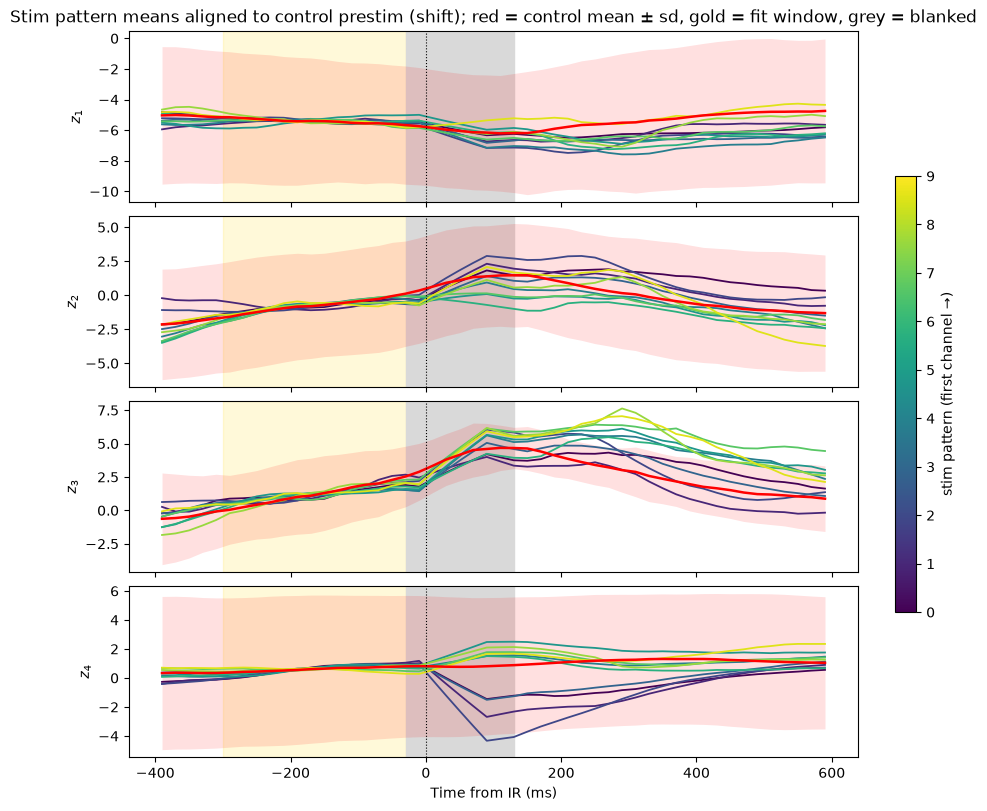

In [13]:
# Same layout as the right column above, with each pattern mapped onto control's prestim.
# Gold band marks the bins the alignment was fit on.
fig, axes = plt.subplots(STATE_DIM, 1, figsize=(9, 2.0 * STATE_DIM), constrained_layout=True, sharex=True)
for k, ax in enumerate(axes):
    for j, color in enumerate(colors):
        ax.plot(t_ms[tp], z_stim_al[pattern_id == j][:, tp, k].mean(axis=0), color=color, lw=1.3)
    m, sd = mean_control[tp, k], z_control[:, tp, k].std(axis=0)
    ax.fill_between(t_ms[tp], m - sd, m + sd, color="r", alpha=0.12, lw=0)
    ax.plot(t_ms[tp], m, color="r", lw=1.8)
    ax.axvspan(*ALIGN_PRE_MS, color="gold", alpha=0.15, zorder=0)
    ax.axvspan(*blank_ms, color="0.85", zorder=0)
    ax.axvline(0, color="k", ls=":", lw=0.8)
    ax.set_ylabel(f"$z_{k + 1}$")
axes[0].set_title(f"Stim pattern means aligned to control prestim ({ALIGN_MODE}); "
                  "red = control mean ± sd, gold = fit window, grey = blanked")
axes[-1].set_xlabel("Time from IR (ms)")
fig.colorbar(sm, ax=axes, label="stim pattern (first channel →)", shrink=0.6)
plt.show()

## Fan plane: where the stim conditions differ

The z axes are ordered by overall latent variance, so the differences between stim conditions
are spread thinly over all four panels. Here the aligned pattern means are projected onto the
two directions along which they differ most after the blanking: PCA of the pattern means
minus their across-pattern mean, over the post-blank window. Only measured bins (after the
blanking ends) set the axes, since the trajectory inside the blanked window comes from the
model alone (dynamics + B u). Ellipses are ±2 SEM of each pattern mean, from its trials.

With `FAN_REMOVE_SHARED`, the average stim trajectory (the time course every condition shares)
is subtracted at each time point first, so the plot shows only how the conditions differ from
each other: they start at the origin and fan out. Control is drawn relative to the same average.

With `FAN_EQUAL_AXES`, each fan axis is divided by the between-pattern sd along it, so PC1 and
PC2 get equal visual weight. That stretches the smaller axis: distances are then in sd units per
axis, not latent units, so angles and lengths are not comparable across axes.

between-pattern variance in the fan plane: PC1 0.69, PC2 0.18, total 0.88


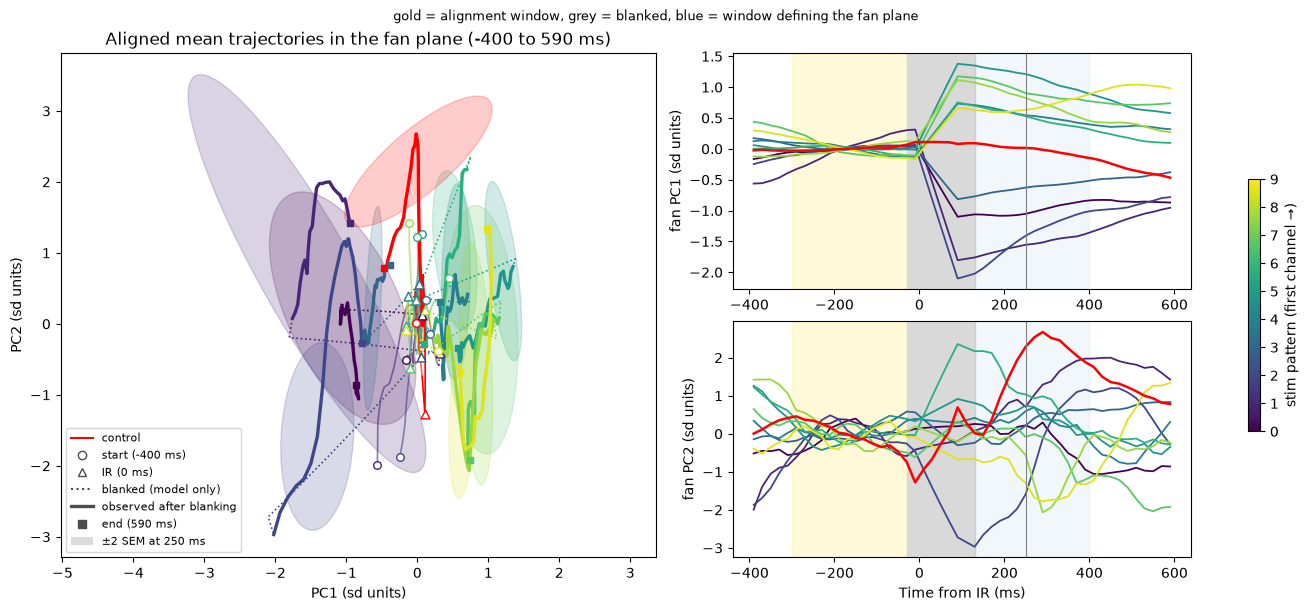

In [14]:
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse

FAN_WIN_MS = (blank_ms[1], 400.0)  # measured post-stim bins that define the fan plane
FAN_EQUAL_AXES = True              # scale each fan axis to unit between-pattern sd
FAN_REMOVE_SHARED = True           # subtract the average stim trajectory at each time
ELLIPSE_MS = 250.0                 # time of the ±2 SEM snapshot

fan_win = (t_ms >= FAN_WIN_MS[0]) & (t_ms <= FAN_WIN_MS[1])
means_al = np.stack([z_stim_al[pattern_id == j].mean(axis=0) for j in range(len(patterns))])  # (P, T, K)

# PCA of the between-pattern differences in the post-blank window
between = means_al[:, fan_win] - means_al[:, fan_win].mean(axis=0)
_, sv, Vt = np.linalg.svd(between.reshape(-1, STATE_DIM), full_matrices=False)
U_fan = Vt[:2].T  # (K, 2), orthonormal
frac = sv**2 / (sv**2).sum()
print(f"between-pattern variance in the fan plane: PC1 {frac[0]:.2f}, PC2 {frac[1]:.2f}, "
      f"total {frac[:2].sum():.2f}")

# Between-pattern sd along each fan axis (the first three, the 3-D view uses PC3)
fan_scale = sv[:3] / np.sqrt(between.shape[0] * between.shape[1]) if FAN_EQUAL_AXES else np.ones(3)
axis_unit = " (sd units)" if FAN_EQUAL_AXES else ""

# Origin at the shared prestim state, so every condition starts near (0, 0)
# shared: (T, K) time course common to all stim conditions, removed if FAN_REMOVE_SHARED
shared = means_al.mean(axis=0) if FAN_REMOVE_SHARED else np.zeros_like(mean_control)
origin = (mean_control - shared)[pre_mask].mean(axis=0) @ U_fan


def to_fan(z, t=slice(None)):
    """Fan-plane coordinates of z (..., T, K), or of z (..., K) at time index t."""
    return ((z - shared[t]) @ U_fan - origin) / fan_scale[:2]


fan_means = to_fan(means_al)
fan_control = to_fan(mean_control)

t_plot = t_ms[tp]
i_lo, i_hi = np.flatnonzero(t_plot <= blank_ms[0])[-1], np.flatnonzero(t_plot >= blank_ms[1])[0]
i_zero = int(np.argmin(np.abs(t_plot)))
i_ell = int(np.argmin(np.abs(t_ms - ELLIPSE_MS)))


def draw_path(ax, P, color, lw, blanked=True):
    """Thin before stim, dotted over the blanked bins (if `blanked`), thick once spikes are
    observed again."""
    ax.plot(*P[: i_lo + 1].T, color=color, lw=0.8 * lw, alpha=0.6)
    ax.plot(*P[i_lo : i_hi + 1].T, color=color, lw=0.8 * lw, ls=":" if blanked else "-")
    ax.plot(*P[i_hi:].T, color=color, lw=1.6 * lw)
    ax.scatter(*P[0], marker="o", s=30, facecolor="white", edgecolor=color, zorder=5)
    ax.scatter(*P[i_zero], marker="^", s=40, facecolor="white", edgecolor=color, zorder=5)
    ax.scatter(*P[-1], marker="s", s=25, color=color, zorder=5)


def sem_ellipse(ax, pts, color):
    """±2 SEM ellipse of the mean of `pts` (n, 2)."""
    cov = np.cov(pts.T) / len(pts)
    evals, evecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(evecs[1, -1], evecs[0, -1]))
    ax.add_patch(Ellipse(pts.mean(axis=0), *(4 * np.sqrt(evals[::-1])), angle=angle,
                         facecolor=color, edgecolor=color, alpha=0.2, lw=1))


fig = plt.figure(figsize=(13, 6), constrained_layout=True)
grid = fig.add_gridspec(2, 2, width_ratios=[1.3, 1])
ax = fig.add_subplot(grid[:, 0])
for j, color in enumerate(colors):
    draw_path(ax, fan_means[j, tp], color, lw=1.5)
    sem_ellipse(ax, to_fan(z_stim_al[pattern_id == j][:, i_ell], i_ell), color)
draw_path(ax, fan_control[tp], "r", lw=1.5, blanked=False)  # control was never blanked
sem_ellipse(ax, to_fan(z_control[:, i_ell], i_ell), "r")
ax.set_xlabel(f"PC1{axis_unit}"); ax.set_ylabel(f"PC2{axis_unit}"); ax.set_aspect("equal", adjustable="datalim")
ax.set_title(f"Aligned mean trajectories in the fan plane ({PLOT_FROM_MS:.0f} to {t_plot[-1]:.0f} ms)")
ink = "0.3"
ax.legend(handles=[
    Line2D([], [], color="r", label="control"),
    Line2D([], [], ls="none", marker="o", mfc="white", mec=ink, label=f"start ({PLOT_FROM_MS:.0f} ms)"),
    Line2D([], [], ls="none", marker="^", mfc="white", mec=ink, label="IR (0 ms)"),
    Line2D([], [], color=ink, ls=":", label="blanked (model only)"),
    Line2D([], [], color=ink, lw=2.4, label="observed after blanking"),
    Line2D([], [], ls="none", marker="s", color=ink, label=f"end ({t_plot[-1]:.0f} ms)"),
    Ellipse((0, 0), 1, 1, facecolor=ink, alpha=0.2, label=f"±2 SEM at {t_ms[i_ell]:.0f} ms"),
], fontsize=8, loc="best")

# The same two coordinates against time: together before stim, apart after
for row in range(2):
    axt = fig.add_subplot(grid[row, 1])
    for j, color in enumerate(colors):
        axt.plot(t_plot, fan_means[j, tp, row], color=color, lw=1.3)
    axt.plot(t_plot, fan_control[tp, row], color="r", lw=1.8)
    axt.axvspan(*ALIGN_PRE_MS, color="gold", alpha=0.15, zorder=0)
    axt.axvspan(*blank_ms, color="0.85", zorder=0)
    axt.axvspan(*FAN_WIN_MS, color="tab:blue", alpha=0.06, zorder=0)
    axt.axvline(t_ms[i_ell], color="0.5", lw=0.8)
    axt.set_ylabel(f"fan PC{row + 1}{axis_unit}")
axt.set_xlabel("Time from IR (ms)")
fig.colorbar(sm, ax=fig.axes, label="stim pattern (first channel →)", shrink=0.5)
fig.suptitle("gold = alignment window, grey = blanked, blue = window defining the fan plane", fontsize=9)
plt.show()

In [1]:
import plotly.colors as pc
import plotly.graph_objects as go
import plotly.io._renderers as _renderers
import nbformat

_renderers.nbformat = nbformat  # plotly's notebook renderer looks this up lazily

# Same fan PC1-3 axes as the next plot, but nothing subtracted and no axis scaling: the shared
# time course is kept, and coordinates are in latent units.
#   "cube": each axis drawn the same length whatever its range, so PC1 is not squashed by the
#           large shared motion on PC2 (a unit is then a different length on each axis)
#   "data": true to scale, a unit is the same length on every axis
RAW_ASPECT = "cube"
U_raw = Vt[:3].T
origin_raw = mean_control[pre_mask].mean(axis=0) @ U_raw
to_raw = lambda zs: zs[..., tp, :] @ U_raw - origin_raw

hover_raw = "%{text}<br>t = %{customdata:.0f} ms"
idx_marks = [0, i_zero, len(t_plot) - 1]
fig_raw = go.Figure()


def add_raw(zs, name, color, width, blanked=True):
    """Mean trajectory: dotted over the blanking if `blanked`, thick once spikes are observed again."""
    m = to_raw(zs.mean(axis=0))
    pieces = [(slice(0, i_lo + 1), "solid", 0.6), (slice(i_lo, i_hi + 1), "dot" if blanked else "solid", 0.6),
              (slice(i_hi, None), "solid", 1.4)]
    for n, (sl, dash, scale) in enumerate(pieces):
        fig_raw.add_trace(go.Scatter3d(
            x=m[sl, 0], y=m[sl, 1], z=m[sl, 2], mode="lines", name=name, legendgroup=name,
            showlegend=(n == 2), line=dict(color=color, width=4, dash=dash),
            text=[name] * len(t_plot[sl]), customdata=t_plot[sl], hovertemplate=hover_raw,
        ))
    fig_raw.add_trace(go.Scatter3d(
        x=m[idx_marks, 0], y=m[idx_marks, 1], z=m[idx_marks, 2], mode="markers",
        marker=dict(size=[4, 5, 4], symbol=["circle-open", "x", "square"], color=color),
        legendgroup=name, showlegend=False,
        text=[f"{name}: start", f"{name}: IR", f"{name}: end"], customdata=t_plot[idx_marks],
        hovertemplate=hover_raw,
    ))


add_raw(z_control, "control", "red", width=6, blanked=False)  # control was never blanked
for j, color in enumerate(pc.sample_colorscale("Viridis", np.linspace(0, 0.95, len(patterns)))):
    first, last = np.flatnonzero(patterns[j])[[0, -1]]
    add_raw(z_stim_al[pattern_id == j], f"stim ch {first}-{last}", color, width=4)

fig_raw.update_layout(
    title=f"Mean trajectories <br>"
          "<sub>thin = before stim, dotted = blanked (model only), thick = observed after blanking; "
          f"o = start ({PLOT_FROM_MS:.0f} ms), x = IR, square = end. Click legend to toggle.</sub>",
    scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3", aspectmode=RAW_ASPECT),
    legend=dict(itemsizing="constant"),
    margin=dict(l=0, r=0, b=0, t=60), width=1000, height=700,
)
# A FigureWidget (needs anywidget) sends the camera back to Python as you rotate, so the next
# cell can read the view angle
fig_raw = go.FigureWidget(fig_raw)
display(fig_raw)

NameError: name 'Vt' is not defined

elev=59.8, azim=112.7
showing: ['control', 'stim ch 0-7', 'stim ch 8-15', 'stim ch 20-27', 'stim ch 32-39', 'stim ch 36-43']


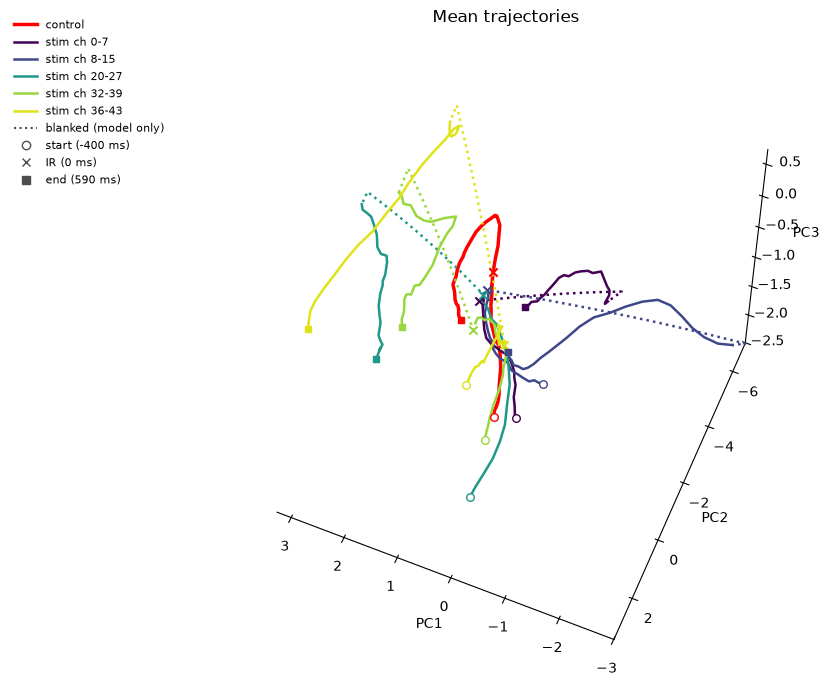

In [ ]:
# Matplotlib copy of the plot above, from the same viewpoint. Rotate the plotly figure first,
# then re-run only this cell: it reads the plotly camera and converts it to (elev, azim).
SAVE_PATH = "../figures/mean_traj_3d.svg"  # e.g. "../figures/mean_traj_3d.png"

# Which conditions to draw:
#   "plotly": the ones currently visible in the plotly figure (click its legend to toggle)
#   a list of names, e.g. ["control", "stim ch 0-7", "stim ch 24-31"]
#   None: all of them
SHOW_CONDITIONS = ["control", "stim ch 0-7", "stim ch 8-15", "stim ch 20-27", "stim ch 32-39", "stim ch 36-43"]


def plotly_view(fig, scene="scene"):
    """(elev, azim) in degrees of a FigureWidget's camera.

    plotly places the camera at `eye`, looking at the centre of the box; an unrotated figure
    has no eye set and uses plotly's default (1.25, 1.25, 1.25).
    """
    eye = fig.layout[scene].camera.eye
    x, y, z = (1.25, 1.25, 1.25) if eye is None or eye.x is None else (eye.x, eye.y, eye.z)
    return float(np.degrees(np.arctan2(z, np.hypot(x, y)))), float(np.degrees(np.arctan2(y, x)))


def plotly_visible(fig):
    """Legend groups not hidden in a FigureWidget (a legend click sets visible="legendonly")."""
    return {t.legendgroup for t in fig.data if t.visible not in (False, "legendonly")}


elev, azim = plotly_view(fig_raw)
print(f"elev={elev:.1f}, azim={azim:.1f}")

stim_names = [f"stim ch {first}-{last}" for first, last in (np.flatnonzero(p)[[0, -1]] for p in patterns)]
if SHOW_CONDITIONS == "plotly":
    shown = plotly_visible(fig_raw)
elif SHOW_CONDITIONS is None:
    shown = {"control", *stim_names}
else:
    shown = set(SHOW_CONDITIONS)
    unknown = shown - {"control", *stim_names}
    assert not unknown, f"unknown conditions {sorted(unknown)}; choose from {['control', *stim_names]}"
print("showing:", [n for n in ["control", *stim_names] if n in shown])

fig = plt.figure(figsize=(8.5, 7))
ax = fig.add_axes([0.2, 0.02, 0.8, 0.9], projection="3d")  # left margin holds the legend
drawn = []


def draw_mean(zs, color, label, lw, blanked=True):
    """Same encoding as the plotly figure: dotted over the blanking, o / x / square markers."""
    m = to_raw(zs.mean(axis=0))
    drawn.append(m)
    ax.plot(*m[: i_lo + 1].T, color=color, lw=lw)
    ax.plot(*m[i_lo : i_hi + 1].T, color=color, lw=lw, ls=":" if blanked else "-")
    ax.plot(*m[i_hi:].T, color=color, lw=lw, label=label)
    ax.scatter(*m[0], marker="o", s=30, facecolor="white", edgecolor=color, depthshade=False, zorder=5)
    ax.scatter(*m[i_zero], marker="x", s=35, color=color, depthshade=False, zorder=5)
    ax.scatter(*m[-1], marker="s", s=22, color=color, depthshade=False, zorder=5)


if "control" in shown:
    draw_mean(z_control, "red", "control", lw=2.5, blanked=False)  # control was never blanked
for j, (color, name) in enumerate(zip(colors, stim_names)):
    if name in shown:
        draw_mean(z_stim_al[pattern_id == j], color, name, lw=1.8)
assert drawn, "no conditions selected"

# Match plotly's box: tight limits around the drawn conditions, then a cube or a true-to-scale box
pts = np.concatenate(drawn)
lo, hi = pts.min(axis=0), pts.max(axis=0)
ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
ax.set_box_aspect((1, 1, 1) if RAW_ASPECT == "cube" else tuple(hi - lo))
ax.set_proj_type("persp")  # plotly draws with perspective by default
ax.view_init(elev=elev, azim=azim)

ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
for pane in (ax.xaxis, ax.yaxis, ax.zaxis):
    pane.set_pane_color((1, 1, 1, 0))
ax.grid(False)
ink = "0.3"
handles, _ = ax.get_legend_handles_labels()
handles += [
    Line2D([], [], color=ink, ls=":", label="blanked (model only)"),
    Line2D([], [], ls="none", marker="o", mfc="white", mec=ink, label=f"start ({PLOT_FROM_MS:.0f} ms)"),
    Line2D([], [], ls="none", marker="x", color=ink, label="IR (0 ms)"),
    Line2D([], [], ls="none", marker="s", color=ink, label=f"end ({t_plot[-1]:.0f} ms)"),
]
fig.legend(handles=handles, fontsize=8, loc="upper left", bbox_to_anchor=(0.01, 0.95), frameon=False)
ax.set_title("Mean trajectories")
if SAVE_PATH:
    fig.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

In [17]:
import plotly.colors as pc
import plotly.graph_objects as go
import plotly.io._renderers as _renderers
import nbformat

_renderers.nbformat = nbformat  # plotly's notebook renderer looks this up lazily

# Axes of the 3-D view, both built on the fan plane from above:
#   "pc3":  fan PC1, PC2, PC3, the three directions along which the conditions differ most
#   "time": time, fan PC1, PC2, so the conditions start as one bundle and split along time
FAN_3D_AXES = "pc3"
SHOW_TRIALS = False  # faint single-trial traces behind the means

if FAN_3D_AXES == "pc3":
    U_3d = Vt[:3].T
    origin_3d = (mean_control - shared)[pre_mask].mean(axis=0) @ U_3d
    to_3d = lambda zs: ((zs - shared)[..., tp, :] @ U_3d - origin_3d) / fan_scale
    axis_titles = tuple(f"PC{k}{axis_unit}" for k in (1, 2, 3))
    print(f"between-pattern variance on PC1-3: {np.round(frac[:3], 2)}, total {frac[:3].sum():.2f}")
elif FAN_3D_AXES == "time":
    def to_3d(zs):
        P = to_fan(zs)[..., tp, :]
        return np.concatenate([np.broadcast_to(t_plot[:, None], P.shape[:-1] + (1,)), P], axis=-1)
    axis_titles = ("time from IR (ms)", f"PC1{axis_unit}", f"PC2{axis_unit}")
else:
    raise ValueError(f"FAN_3D_AXES must be 'pc3' or 'time', got {FAN_3D_AXES!r}")

hover = "%{text}<br>t = %{customdata:.0f} ms"
segments = [(slice(0, i_lo + 1), "solid", 0.6), (slice(i_lo, i_hi + 1), "dot", 0.6), (slice(i_hi, None), "solid", 1.4)]


def add_trajectories(fig, zs, name, color, width, dash="solid", alpha_trials=0.05, blanked=True):
    """The mean (dotted over the blanking if `blanked`, solid otherwise) with start / IR / end
    markers, and faint single trials if SHOW_TRIALS."""
    if SHOW_TRIALS:
        trials = to_3d(zs)
        sep = np.full((trials.shape[0], 1, 3), np.nan)
        flat = np.concatenate([trials, sep], axis=1).reshape(-1, 3)
        fig.add_trace(go.Scatter3d(
            x=flat[:, 0], y=flat[:, 1], z=flat[:, 2], mode="lines",
            line=dict(color=color, width=4), opacity=alpha_trials,
            legendgroup=name, showlegend=False, hoverinfo="skip",
        ))
    m = to_3d(zs.mean(axis=0))
    for n, (sl, seg_dash, scale) in enumerate(segments):
        fig.add_trace(go.Scatter3d(
            x=m[sl, 0], y=m[sl, 1], z=m[sl, 2], mode="lines", name=name, legendgroup=name,
            showlegend=(n == 2), line=dict(color=color, width=4,
                                           dash="dot" if blanked and seg_dash == "dot" else dash),
            text=[name] * len(t_plot[sl]), customdata=t_plot[sl], hovertemplate=hover,
        ))
    idx = [0, i_zero, len(t_plot) - 1]
    fig.add_trace(go.Scatter3d(
        x=m[idx, 0], y=m[idx, 1], z=m[idx, 2], mode="markers",
        marker=dict(size=[4, 5, 4], symbol=["circle-open", "x", "square"], color=color),
        legendgroup=name, showlegend=False,
        text=[f"{name}: start", f"{name}: IR", f"{name}: end"], customdata=t_plot[idx],
        hovertemplate=hover,
    ))


fig = go.Figure()
# Control trials were never blanked, so their whole trajectory is observed
add_trajectories(fig, z_control, "control", "red", width=6, blanked=False)
for j, color in enumerate(pc.sample_colorscale("Viridis", np.linspace(0, 0.95, len(patterns)))):
    first, last = np.flatnonzero(patterns[j])[[0, -1]]
    add_trajectories(fig, z_stim_al[pattern_id == j], f"stim ch {first}-{last}", color, width=4)

fig.update_layout(
    title=f"Difference in mean trajectories"
          f"{', shared time course removed' if FAN_REMOVE_SHARED else ''}<br>"
          f"<sub>thin = before stim, dotted = blanked (model only), thick = observed after blanking; "
          f"o = start ({PLOT_FROM_MS:.0f} ms), x = IR, square = end. Click legend to toggle.</sub>",
    scene=dict(xaxis_title=axis_titles[0], yaxis_title=axis_titles[1], zaxis_title=axis_titles[2],
               aspectmode="cube"),
    legend=dict(itemsizing="constant"),
    margin=dict(l=0, r=0, b=0, t=60), width=1000, height=700,
)
fig.show()

between-pattern variance on PC1-3: [0.69 0.18 0.1 ], total 0.98


# Fit checks

/tmp/ipykernel_9060/644833550.py:10: RuntimeWarning: Mean of empty slice
  ax.plot(t_ms[tp], np.nanmean(Y_np[sel][:, tp, ch], axis=0) * hz, color="0.6", lw=1, label="observed")


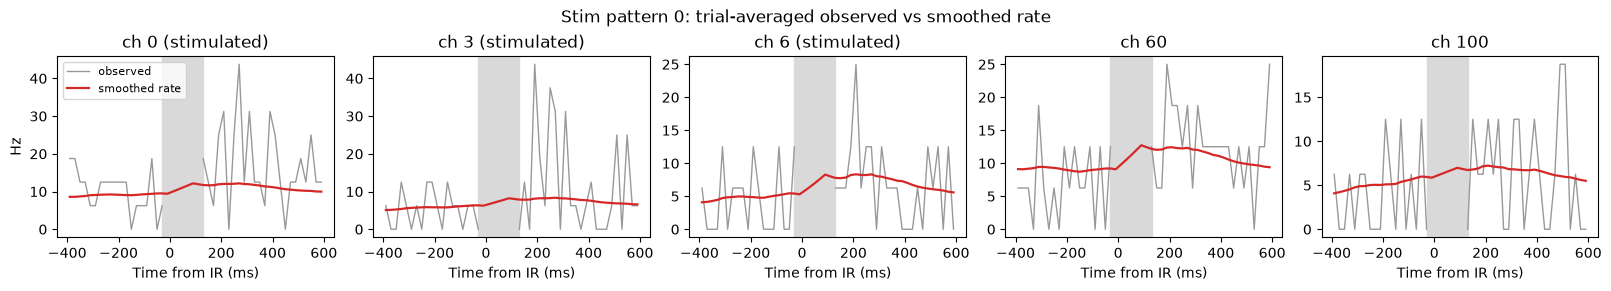

In [18]:
# Smoothed rates against the observed PSTH, for a few channels that are stimulated in pattern 0
rate = np.asarray(softplus(posts.smoothed_means @ model.observation.C.T + model.observation.d, BETA_EMIT))
hz = 1000.0 / np.median(np.diff(t_ms))
Y_np = np.asarray(Y_all)
sel = np.flatnonzero(is_stim)[pattern_id == 0]
chans = np.flatnonzero(patterns[0])[::3][:3].tolist() + [60, 100]

fig, axes = plt.subplots(1, len(chans), figsize=(3.2 * len(chans), 2.8), constrained_layout=True, sharex=True)
for ax, ch in zip(axes, chans):
    ax.plot(t_ms[tp], np.nanmean(Y_np[sel][:, tp, ch], axis=0) * hz, color="0.6", lw=1, label="observed")
    ax.plot(t_ms[tp], rate[sel][:, tp, ch].mean(axis=0) * hz, color="tab:red", lw=1.6, label="smoothed rate")
    ax.axvspan(*blank_ms, color="0.85", zorder=0)
    ax.set_title(f"ch {ch}" + (" (stimulated)" if patterns[0, ch] else ""))
    ax.set_xlabel("Time from IR (ms)")
axes[0].set_ylabel("Hz"); axes[0].legend(fontsize=8)
fig.suptitle("Stim pattern 0: trial-averaged observed vs smoothed rate")
plt.show()

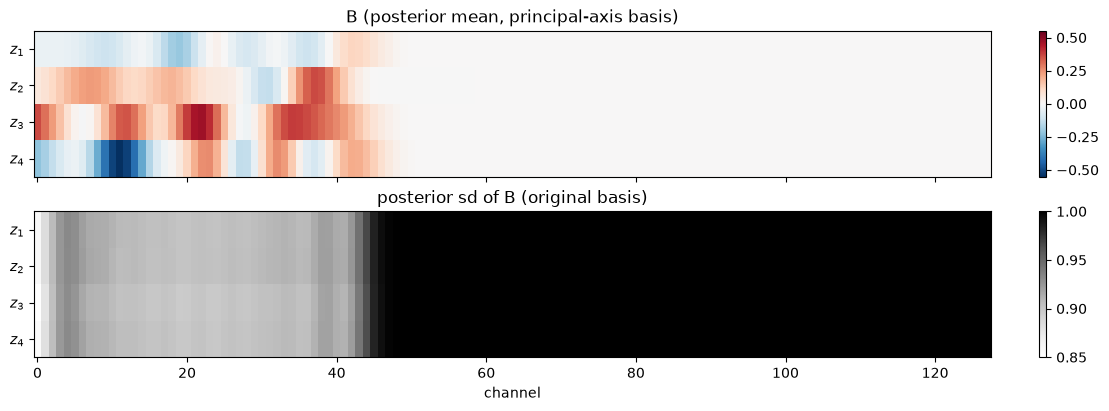

In [19]:
# Fitted B in the principal-axis basis (rows = z, columns = channels), and its posterior sd
B_z = R.T @ np.asarray(B_fit)
B_sd = np.sqrt(np.diag(np.asarray(B_post.cov))).reshape(n_ch, STATE_DIM).T  # vec stacks columns

fig, axes = plt.subplots(2, 1, figsize=(11, 4), constrained_layout=True, sharex=True)
lim = np.abs(B_z).max()
im = axes[0].imshow(B_z, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
fig.colorbar(im, ax=axes[0]); axes[0].set_title("B (posterior mean, principal-axis basis)")
im = axes[1].imshow(B_sd, aspect="auto", cmap="Greys", interpolation="nearest")
fig.colorbar(im, ax=axes[1]); axes[1].set_title("posterior sd of B (original basis)")
axes[1].set_xlabel("channel")
for ax in axes:
    ax.set_yticks(range(STATE_DIM), [f"$z_{k+1}$" for k in range(STATE_DIM)])
plt.show()